# Sympy nachrechnen der Formeln

In [ ]:
# from sympy import *
from sympy import symbols, Matrix
import sympy
theta, delta, phi1, phi2, I0 = symbols('theta delta phi1 phi2 I0')



def MuellerRetarder(delta, theta):
	"""
	Returns the Mueller matrix of a retarder with delta as the phase difference and theta as the orientation angle.
	Both in terms of degrees !!!!
	"""
	delta_rad = delta
	theta_rad = theta
	c_delta = sympy.cos(delta_rad)
	s_delta = sympy.sin(delta_rad)
	c2_theta = sympy.cos(2 * theta_rad)
	s2_theta = sympy.sin(2 * theta_rad)
	M = Matrix([
		[1, 0, 0, 0],
		[0, c2_theta**2 + s2_theta**2 * c_delta, c2_theta * s2_theta * (1 - c_delta), s2_theta * s_delta],
		[0, c2_theta * s2_theta * (1 - c_delta), s2_theta**2 + c2_theta**2 * c_delta, -c2_theta * s_delta],
		[0, -s2_theta * s_delta, c2_theta * s_delta, c_delta]
	])
	return M

Retarder = MuellerRetarder(delta, theta)
Retarder.subs(theta, sympy.pi/4)

Matrix([
[1,           0, 0,          0],
[0,  cos(delta), 0, sin(delta)],
[0,           0, 1,          0],
[0, -sin(delta), 0, cos(delta)]])

In [ ]:
def MuellerLinearPolarizer(theta):
    """
    Returns the Mueller matrix of a linear polarizer with orientation angle theta.
    In terms of degrees !!!!
    """
    theta_rad =theta
    c2_theta = sympy.cos(2 * theta_rad)
    s2_theta = sympy.sin(2 * theta_rad)

    M = 0.5 * Matrix([
        [1, c2_theta, s2_theta, 0],
        [c2_theta, c2_theta**2, c2_theta * s2_theta, 0],
        [s2_theta, c2_theta * s2_theta, s2_theta**2, 0],
        [0, 0, 0, 0]
    ])
    return M
Pol1 = MuellerLinearPolarizer(phi1)
Pol2 = MuellerLinearPolarizer(phi2)

Pol1.subs(phi1, 0)

Matrix([
[0.5, 0.5, 0, 0],
[0.5, 0.5, 0, 0],
[  0,   0, 0, 0],
[  0,   0, 0, 0]])

In [ ]:
Pol2.subs(phi2, sympy.pi/2)

Matrix([
[ 0.5, -0.5, 0, 0],
[-0.5,  0.5, 0, 0],
[   0,    0, 0, 0],
[   0,    0, 0, 0]])

In [ ]:
(Pol1.subs(phi1, 0) @ Retarder.subs(theta, sympy.pi/4) @ Pol2.subs(phi2, sympy.pi/2) @ Matrix([I0, 0, 0, 0]))[0]

I0*(0.25 - 0.25*cos(delta))

Die funktion sollte also korrekt sein

# Calibration LCR

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
fileRoots = []
for root, dirs, files in os.walk("data/LCR/"):
    for file in files:
        if file.endswith(".csv"):
            fileRoots.append(os.path.join(root, file))
            print(f"Found file: {file}")

measurements = []
names = []
for file in fileRoots:
    temp = np.loadtxt(file, delimiter=",", dtype=str)
    measurements.append(np.array(temp[1:, :], dtype=float))
    names.append(temp[0, :])

measurements = np.array(measurements)
names

Found file: lcvr-calibration-lcvr1.csv
Found file: lcvr-calibration-lcvr2.csv
Found file: lcvr-calibration-lcvr3.csv
Found file: lcvr-calibration-lcvr4.csv


C:\Users\tlock\AppData\Local\Temp\ipykernel_8088\1397888537.py:14: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  temp = np.loadtxt(file, delimiter=",", dtype=str)


[array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18'),
 array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18'),
 array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18'),
 array(['step', 'voltage_set_v', 'voltage_read_v', 'exposure_ms', 'mean',
        'max', 'mean_r', 'mean_g', 'mean_b'], dtype='<U18')]

Text(0, 0.5, 'Intensities mean_g')

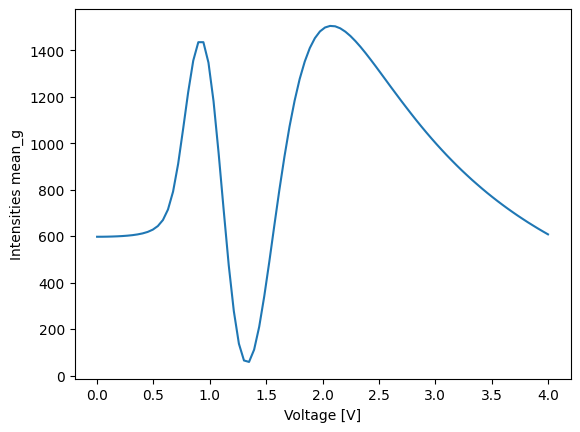

In [11]:
plt.plot(measurements[0,:,2], measurements[0,:,7])
plt.xlabel("Voltage [V]")
plt.ylabel(f"Intensities {names[0][7]}")

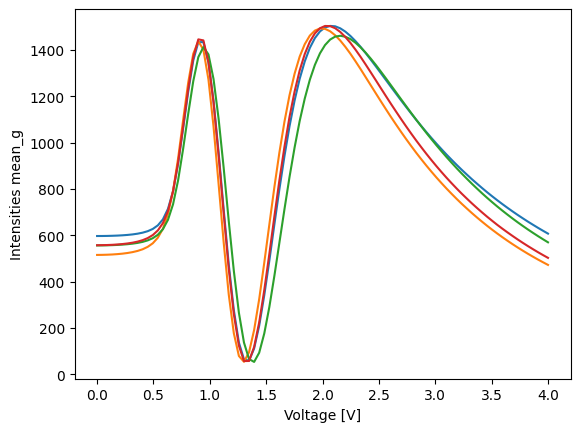

In [12]:
for i in range(len(measurements)):
    plt.plot(measurements[i,:,2], measurements[i,:,7], label=f"Measurement {i+1}")
    plt.xlabel("Voltage [V]")
    plt.ylabel(f"Intensities {names[i][7]}")

In [13]:
from lmfit.models import Model
# 3000, -3.97, 9.97, -3.90, 0.454, 1.35
# def intens(x, Intensity=3000, a=-3.97, b=9.97, c=-3.90, d=0.454, e=1.35, f=0.1, g=0.1, h=0.1, i=0.1):
#     return 1/4 * (Intensity-Intensity*np.cos(a*x+b*x**2 + c*x**3 + d * x**4 + e *x**5 + f * x**6 + g * x**7 + h * x**8 + i))

# def intens(x, Intensity=1, a=0.1, b=0.1, mu1=0.05, lam1=-0.1, mu2=0.5, lam2=0.1):
#     return 1/4 * (Intensity-Intensity*np.cos(a*x+b*x*np.exp((x-mu1)*lam1+(x-mu2)*lam2)))


# sehr gut
# def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
#     t = (np.abs(x)/c)**d
#     return 1/4 * (Intensity-Intensity*np.cos(a + b * t/(1 + t) + + e*np.log1p(t))) #e*x

def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
    return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

def ret(x, a, b, c, d, e):
    return a*np.deg2rad(x)+b*np.deg2rad(x)**2 + c*np.deg2rad(x)**3 + d * np.deg2rad(x)**4 + e

mod = Model(intens)#GaussianModel(prefix = "a")+GaussianModel(prefix = "b")

pars = mod.make_params()
pars


name,value,initial value,min,max,vary
Intensity,3000.00000,None,-inf,inf,True
a,1.10000000,None,-inf,inf,True
b,8.40000000,None,-inf,inf,True
c,1.28000000,None,-inf,inf,True
d,4.30000000,None,-inf,inf,True
e,0.45000000,None,-inf,inf,True


In [5]:
def update_model(fileindex,xName="Spannung [V]", yName="Intensität Grün", yDataErr=0.1, xDataErr=0.1, **params):
    # Setze die Werte der Parameter
    for name, value in params.items():
        pars[name].value = value

    # Berechne Modell mit aktuellen Parametern
    x = measurements[fileindex,:,2]
    x_fit = np.arange(x.min(), x.max(), (x.max() - x.min())/10000)
    y_fit = mod.eval(pars, x=x_fit)

    # Plotten der Daten und des Modells
    plt.figure(figsize=(8, 6))
    plt.errorbar(y = measurements[fileindex,:,7], yerr = yDataErr, x = measurements[fileindex,:,2], xerr = xDataErr, \
        fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, \
        label = r'Werte')
    
    plt.plot(x_fit, y_fit, label="Modell", color='red')
    
    plt.ylabel(yName, fontsize=20)
    plt.xlabel(xName, fontsize=20)
    plt.title('Models')
    result = mod.fit(measurements[fileindex,:,7], pars, x=measurements[fileindex,:,2])
    dynamic_resolution_array = np.arange(min(measurements[fileindex,:,2]),max(measurements[fileindex,:,2]), 0.001*abs(max(measurements[fileindex,:,2])-min(measurements[fileindex,:,2])))
    plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'b-', label = r'Fit')
    plt.tight_layout()
    plt.legend()
    plt.show()
    print(result.fit_report)
    

In [6]:
from ipywidgets import interact, FloatText, IntText, fixed, Textarea
param_widgets = {}
for param_name, param in pars.items():
    param_widgets[param_name] = FloatText(value=param.value,
                                            step=0.1,
                                            description=param_name)

# Interaktive Anzeige mit automatisch generierten Slidern
interact(update_model, fileindex=IntText(value=0), **param_widgets)
print()

interactive(children=(IntText(value=0, description='fileindex'), Text(value='Spannung [V]', description='xName…

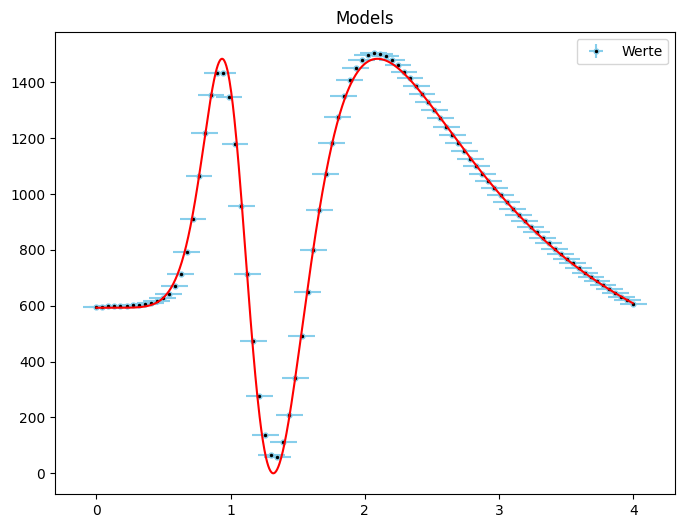

In [14]:
Index = 0
mod = Model(intens)#GaussianModel(prefix = "a")+GaussianModel(prefix = "b")

pars = mod.make_params()
pars
result = mod.fit(measurements[Index,:,7], pars, x=measurements[Index,:,2])
dynamic_resolution_array = np.arange(min(measurements[Index,:,2]),max(measurements[Index,:,2]), 0.001*abs(max(measurements[Index,:,2])-min(measurements[Index,:,2])))

plt.figure(figsize=(8, 6))
plt.errorbar(y = measurements[Index,:,7], yerr = 0.1, x = measurements[Index,:,2], xerr = 0.1, \
    fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, \
    label = r'Werte')

#plt.plot(x_fit, y_fit, label="Modell", color='red')
plt.legend()

plt.title('Models')

plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ')

plt.show()

In [15]:
result

In [9]:
for key in result.params:
    print(key)

Intensity
a
b
c
d
e


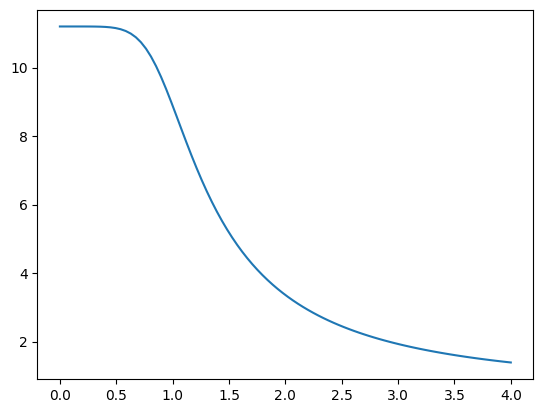

In [9]:
# def ret (x, a, b, c, d, e):
#     return a*np.deg2rad(x)+b*np.deg2rad(x)**2 + c*np.deg2rad(x)**3 + d * np.deg2rad(x)**4 + e
# def ret(x, a, b, c, d, e):
# 	t = (np.abs(x)/c)**d
# 	return a + b * t/(1 + t) + + e*np.log1p(t)
def ret(x, a, b, c, d, e):
    return a + b /(1+(x/c)**d)**e

plt.plot(measurements[0,:,2], ret(measurements[0,:,2], result.params["a"], result.params["b"], result.params["c"], result.params["d"], result.params["e"]))

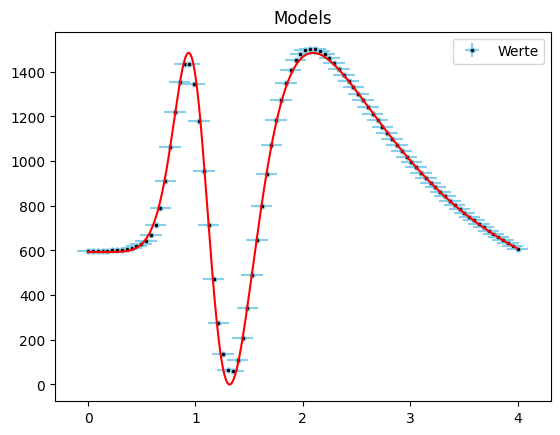

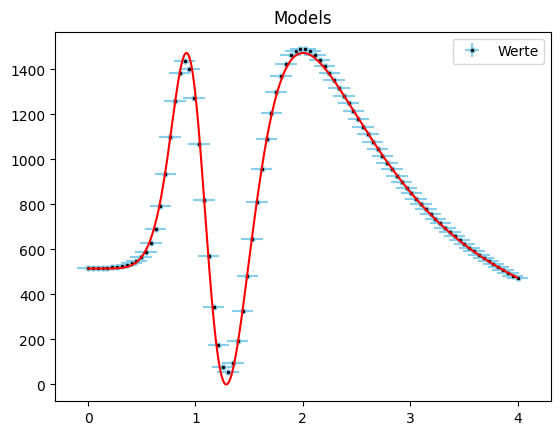

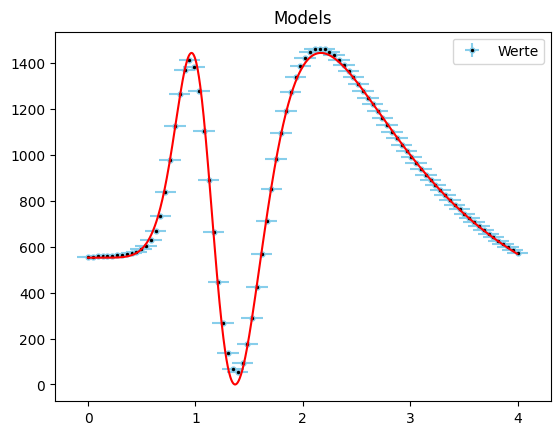

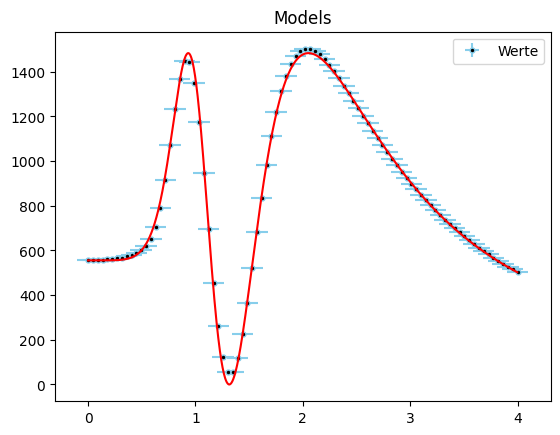

In [18]:
Index = 0


def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
    return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

def ret(x, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
    return a + b /(1+(x/c)**d)**e

mod = Model(intens)#GaussianModel(prefix = "a")+GaussianModel(prefix = "b")

pars = mod.make_params()
pars
for Index in range(4):
	result = mod.fit(measurements[Index,:,7], pars, x=measurements[Index,:,2])
	dynamic_resolution_array = np.arange(min(measurements[Index,:,2]),max(measurements[Index,:,2]), 0.001*abs(max(measurements[Index,:,2])-min(measurements[Index,:,2])))


	plt.errorbar(y = measurements[Index,:,7], yerr = 0.1, x = measurements[Index,:,2], xerr = 0.1, \
		fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, \
		label = r'Werte')

	#plt.plot(x_fit, y_fit, label="Modell", color='red')
	plt.legend()

	plt.title('Models')

	plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ')

	plt.show()

	# plt.plot(measurements[0,:,2], ret(measurements[0,:,2], result.params["a"], result.params["b"], result.params["c"], result.params["d"], result.params["e"]))
	# plt.show()

# Klasse erstellen

In [2]:
class Datensatz:
	__rawData = []
	__DataNames = []
	__greenIntensity = []
	__Volts = []
	__result = []
	__numberOfFiles = 0
	def get_Volts(self):
		return self.__Volts
	def get_GreenIntensities(self):
		return self.__greenIntensity
	def get_rawData(self):
		return self.__rawData
	def get_DataNames(self):
		return self.__DataNames
	def get_Res(self):
		return self.__result
	def get_NumFiles(self):
		return self.__numberOfFiles
	
	
	def __init__(self, path=None):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []
		self.__result = []
		self.__numberOfFiles = 0
		if path != None:
			self.__numberOfFiles += 1
			temp = np.loadtxt(path, delimiter=",", dtype=str)
			self.__rawData.append(np.array(temp[1:, :], dtype=float))
			self.__DataNames.append(np.array(temp[0, :]))
			self.__greenIntensity.append(self.__rawData[-1][:,7])
			self.__Volts.append(self.__rawData[-1][:,2])
		return

	def addFile(self, path):
		temp = np.loadtxt(path, delimiter=",", dtype=str)
		self.__numberOfFiles += 1
		self.__rawData.append(np.array(temp[1:, :], dtype=float))
		self.__DataNames.append(np.array(temp[0, :]))
		self.__greenIntensity.append(self.__rawData[-1][:,7])
		self.__Volts.append(self.__rawData[-1][:,2])
		return

	

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
fileRoots = []
for root, dirs, files in os.walk("data/LCR/"):
    for file in files:
        if file.endswith(".csv"):
            fileRoots.append(os.path.join(root, file))
            print(f"Found file: {file}")



Found file: lcvr-calibration-lcvr1.csv
Found file: lcvr-calibration-lcvr2.csv
Found file: lcvr-calibration-lcvr3.csv
Found file: lcvr-calibration-lcvr4.csv


In [9]:
Test = Datensatz()
for path in fileRoots:
	Test.addFile(path)
len((Test.get_GreenIntensities()))

C:\Users\tlock\AppData\Local\Temp\ipykernel_32352\3024519937.py:39: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  temp = np.loadtxt(path, delimiter=",", dtype=str)


4

In [4]:
import os
name = "Run1"
def createArchitecture(name):
	Architektur = ["LCR_Calibration/LCR1", "LCR_Calibration/LCR2", "LCR_Calibration/LCR3", "LCR_Calibration/LCR4",
				"EVCalibration/Probe1", "EVCalibration/Probe2", "EVCalibration/Probe3", "EVCalibration/Probe4",  
				"Measurements/"
				]
	for ordner in Architektur:
		os.makedirs(f"./data/{name}/{ordner}", exist_ok=True)
	return None

In [ ]:
import os
def getFilesOfType(pathStr:str, Type:str=".csv"):
	csv_dateien = [
		datei for datei in os.listdir(f"./data/Run1/{pathStr}")
		if datei.lower().endswith(".csv")]
	return csv_dateien

getFilesOfType("LCR_Calibration/LCR1")

['lcvr-calibration-lcvr1.csv']

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
from tqdm import tqdm
import os
from lmfit.models import Model
from lmfit.model import save_modelresult

class Datensatz:
	__rawData = []
	__DataNames = []
	__greenIntensity = []
	__Volts = []
	__numberOfFiles = 0
	__Architektur = ["LCR_Calibration/LCR1", "LCR_Calibration/LCR2", "LCR_Calibration/LCR3", "LCR_Calibration/LCR4",
					"EVCalibration/Probe1", "EVCalibration/Probe2", "EVCalibration/Probe3", "EVCalibration/Probe4",  
					"Measurements/"
					]
	__RunName = "test"
	
	def get_Volts(self):
		return self.__Volts
	def get_GreenIntensities(self):
		return self.__greenIntensity
	def get_rawData(self):
		return self.__rawData
	def get_DataNames(self):
		return self.__DataNames
	def get_NumFiles(self):
		return self.__numberOfFiles
	def get_RunName(self):
			return self.__RunName

	def getFilesOfType(self, pathStr:str, Type:str=".csv"):
		DateienOfType = [
			datei for datei in os.listdir(f"./data/{self.__RunName}/{pathStr}")
			if datei.lower().endswith(".csv")
		]
		return DateienOfType
	
	def __init__(self, RunName:str = None, numerOfRetarders:int = 4, Type:str = None):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []
		self.__numberOfFiles = 0
		self.__RunName = "test"
		if RunName != None:
			self.__RunName = RunName
			for index in range(numerOfRetarders):
				temp = self.getFilesOfType(self.__Architektur[index], Type)
				if len(temp) == 1:
					path = f"./data/{self.__RunName}/{self.__Architektur[index]}/{temp[0]}"
				else:
					print(f"There are {len(temp)} csv Files within directory ./data/{self.__RunName}/{self.__Architektur[index]}, please only supply a singular file for nonabiguity")
				self.__numberOfFiles += 1
				temp = np.loadtxt(path, delimiter=",", dtype=str)
				self.__rawData.append(np.array(temp[1:, :], dtype=float))
				self.__DataNames.append(np.array(temp[0, :]))
				self.__greenIntensity.append(self.__rawData[-1][:,7])
				self.__Volts.append(self.__rawData[-1][:,2])
		return print(index, " files have beein loaded")

	def addFile(self, path:str):
		temp = np.loadtxt(path, delimiter=",", dtype=str)
		self.__numberOfFiles += 1
		self.__rawData.append(np.array(temp[1:, :], dtype=float))
		self.__DataNames.append(np.array(temp[0, :]))
		self.__greenIntensity.append(self.__rawData[-1][:,7])
		self.__Volts.append(self.__rawData[-1][:,2])
		return

	def createArchitecture(self, name = None):
		if name != None:
			self.__RunName = name
		for ordner in self.__Architektur:
			os.makedirs(f"./data/{self.__RunName}/{ordner}", exist_ok=True)
		return None

	def fitLCR(self, numberOfRetarder = 4, y_err = 1, xLabel = "Volts [V]", yLabel = "Intensity"):
		def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

		mod = Model(intens)
		pars = mod.make_params()

		for Index in range(numberOfRetarder):
			result = mod.fit(self.__greenIntensity[Index], pars, x=self.__Volts[Index])
			dynamic_resolution_array = np.arange(min(self.__Volts[Index]),max(self.__Volts[Index]), 0.001*abs(max(self.__Volts[Index])-min(self.__Volts[Index])))
			fig = plt.figure(figsize=(9,6), dpi=80)
			plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ' + f"{result.result.redchi:.3}")
			plt.errorbar(
				y = self.__greenIntensity[Index], 
				x = self.__Volts[Index], 
				yerr = y_err,
				fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, label = r'Werte'
				) #xerr = x_err, yerr = y_err, 
			plt.legend(loc='best')
	
			plt.ylabel(yLabel, fontsize=20)
			plt.xlabel(xLabel, fontsize=20)
	
			plt.legend(fontsize=12)
			plt.xticks(fontsize=16)
			plt.yticks(fontsize=16)
			plt.tight_layout()
			fig.savefig(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_Fit.pdf")
			plt.show()
			save_modelresult(result, f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")

	def getVoltageMap(self, Retardences:np.ndarray ,NumberOfRetarders:int = 4):
		# def ret(x, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
		# 	return a + b /(1+(x/c)**d)**e
		def retInv(x, a=0.6, b=10, c=1, d=6.4, e=0.3):
			return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)
		Voltage_lst = []
		for Index in range(NumberOfRetarders):
			result = load_model(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")
			Keys = [key for key in result.params]
			Voltages = retInv(Retardences, result.params[Keys[1]].value, result.params[Keys[2]].value, result.params[Keys[3]].value, result.params[Keys[4]].value, result.params[Keys[5]].value, result.params[Keys[6]].value)
			Voltage_lst.append(Voltages)
		return Voltage_lst
			

In [38]:
def ret(x, a=0.6, b=10, c=1, d=6.4, e=0.3):
	return a + b /(1+(x/c)**d)**e

def retInv(x, a=0.6, b=10, c=1, d=6.4, e=0.3):
	return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)

C:\Users\tlock\AppData\Local\Temp\ipykernel_8088\932292496.py:5: RuntimeWarning: invalid value encountered in power
  return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)


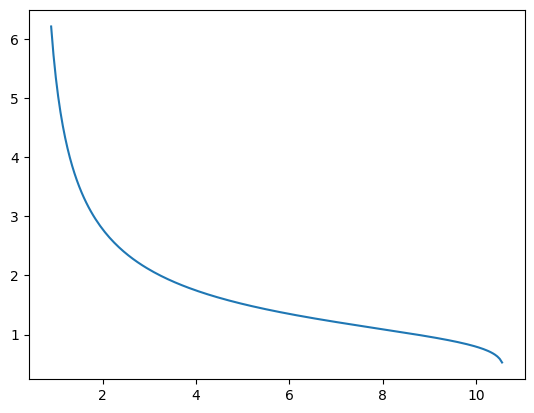

In [45]:
liste = np.arange(0.9, 12, 0.05)
plt.plot(liste, retInv(liste))


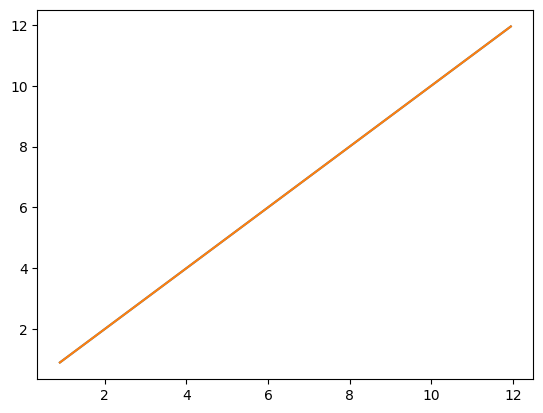

In [42]:
plt.plot(liste, retInv(ret(liste)))
plt.plot(liste, liste)

In [ ]:
from lmfit.model import save_modelresult, load_model

In [27]:
Keys = [key for key in result.params]
result

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
from tqdm import tqdm
import os
from lmfit.models import Model
from lmfit.model import save_modelresult, load_modelresult
from tifffile import imwrite, imread

class Datensatz:
	__rawData = []
	__DataNames = []
	__greenIntensity = []
	__Volts = []
	__numberOfFiles = 0
	__Architektur = ["LCR_Calibration/LCR1", "LCR_Calibration/LCR2", "LCR_Calibration/LCR3", "LCR_Calibration/LCR4",
					"EVCalibration/Probe1", "EVCalibration/Probe2", "EVCalibration/Probe3", "EVCalibration/Probe4",  
					"Measurements/"
					]
	__RunName = "test"
	
	def get_Volts(self):
		return self.__Volts
	def get_GreenIntensities(self):
		return self.__greenIntensity
	def get_rawData(self):
		return self.__rawData
	def get_DataNames(self):
		return self.__DataNames
	def get_NumFiles(self):
		return self.__numberOfFiles
	def get_RunName(self):
			return self.__RunName

	def getFilesOfType(self, pathStr:str, Type:str=".csv"):
		DateienOfType = [
			datei for datei in os.listdir(f"./data/{self.__RunName}/{pathStr}")
			if datei.lower().endswith(".csv")
		]
		return DateienOfType
	
	def __init__(self, RunName:str = None, numerOfRetarders:int = 4, Type:str = None):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []
		self.__numberOfFiles = 0
		self.__RunName = "test"
		if RunName != None:
			self.__RunName = RunName
			for index in range(numerOfRetarders):
				temp = self.getFilesOfType(self.__Architektur[index], Type)
				if len(temp) == 1:
					path = f"./data/{self.__RunName}/{self.__Architektur[index]}/{temp[0]}"
				else:
					print(f"There are {len(temp)} csv Files within directory ./data/{self.__RunName}/{self.__Architektur[index]}, please only supply a singular file for nonabiguity")
				self.__numberOfFiles += 1
				temp = np.loadtxt(path, delimiter=",", dtype=str)
				self.__rawData.append(np.array(temp[1:, :], dtype=float))
				self.__DataNames.append(np.array(temp[0, :]))
				self.__greenIntensity.append(self.__rawData[-1][:,7])
				self.__Volts.append(self.__rawData[-1][:,2])
		return print(index, " files have beein loaded")

	def addFile(self, path:str):
		temp = np.loadtxt(path, delimiter=",", dtype=str)
		self.__numberOfFiles += 1
		self.__rawData.append(np.array(temp[1:, :], dtype=float))
		self.__DataNames.append(np.array(temp[0, :]))
		self.__greenIntensity.append(self.__rawData[-1][:,7])
		self.__Volts.append(self.__rawData[-1][:,2])
		return

	def createArchitecture(self, name = None):
		if name != None:
			self.__RunName = name
		for ordner in self.__Architektur:
			os.makedirs(f"./data/{self.__RunName}/{ordner}", exist_ok=True)
		return None

	def fitLCR(self, numberOfRetarder = 4, y_err = 1, xLabel = "Volts [V]", yLabel = "Intensity"):
		def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

		mod = Model(intens)
		pars = mod.make_params()

		for Index in range(numberOfRetarder):
			result = mod.fit(self.__greenIntensity[Index], pars, x=self.__Volts[Index])
			dynamic_resolution_array = np.arange(min(self.__Volts[Index]),max(self.__Volts[Index]), 0.001*abs(max(self.__Volts[Index])-min(self.__Volts[Index])))
			fig = plt.figure(figsize=(9,6), dpi=80)
			plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ' + f"{result.result.redchi:.3}")
			plt.errorbar(
				y = self.__greenIntensity[Index], 
				x = self.__Volts[Index], 
				yerr = y_err,
				fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, label = r'Werte'
				) #xerr = x_err, yerr = y_err, 
			plt.legend(loc='best')
	
			plt.ylabel(yLabel, fontsize=20)
			plt.xlabel(xLabel, fontsize=20)
	
			plt.legend(fontsize=12)
			plt.xticks(fontsize=16)
			plt.yticks(fontsize=16)
			plt.tight_layout()
			fig.savefig(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_Fit.pdf")
			plt.show()
			save_modelresult(result, f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")

	def getVoltageMap(self, Retardences:np.ndarray ,NumberOfRetarders:int = 4):
		# def ret(x, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
		# 	return a + b /(1+(x/c)**d)**e
		def retInv(x, a=0.6, b=10, c=1, d=6.4, e=0.3):
			return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)
		Voltage_lst = []
		for Index in range(NumberOfRetarders):
			result = load_modelresult(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")
			Keys = [key for key in result.params]
			Voltages = retInv(Retardences, result.params[Keys[1]].value, result.params[Keys[2]].value, result.params[Keys[3]].value, result.params[Keys[4]].value, result.params[Keys[5]].value)
			Voltage_lst.append(Voltages)
			imwrite(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_VoltageList.tif", Voltages)
		return Voltage_lst

def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

3  files have beein loaded


e:\pythonReps\Masterarbeit\MuellerLib.py:390: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  temp = np.loadtxt(path, delimiter=",", dtype=str)


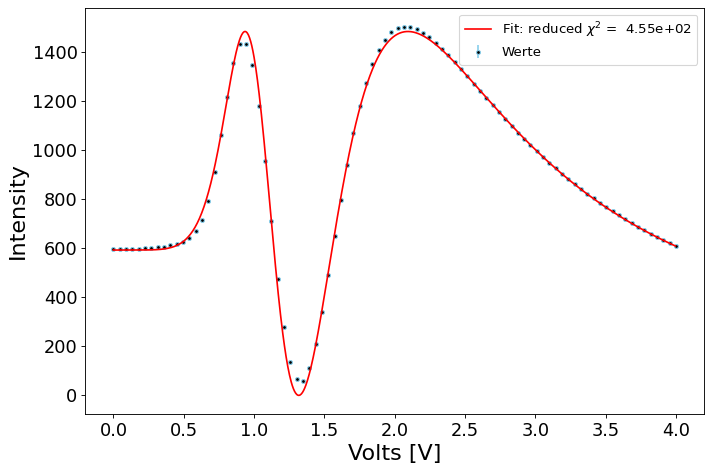

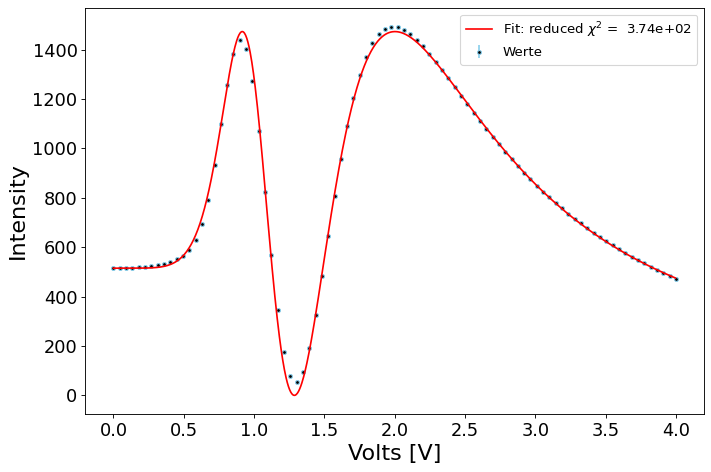

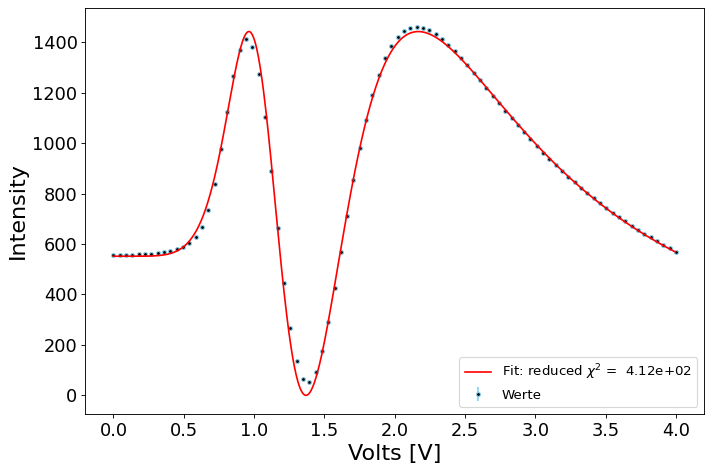

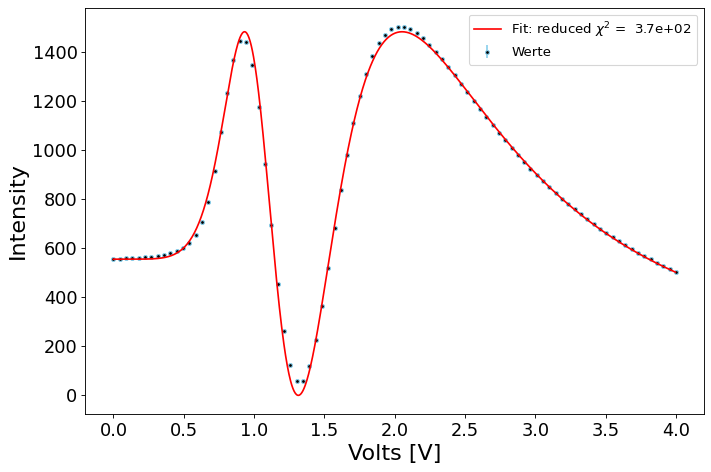

e:\pythonReps\Masterarbeit\MuellerLib.py:448: RuntimeWarning: invalid value encountered in power
  return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)


[array([12.29488015,  8.48135255,  6.80349243,  5.81312457,  5.14334646,
         4.65286083,  4.27432872,  3.97110884,  3.72135734,  3.51114923,
         3.33113927,  3.17479493,  3.03739604,  2.91543698,  2.80625317,
         2.70777876,  2.61838447,  2.53676594,  2.46186506,  2.39281337,
         2.32889059,  2.26949364,  2.21411328,  2.16231612,  2.11373076,
         2.06803677,  2.02495612,  1.98424617,  1.9456941 ,  1.90911237,
         1.87433493,  1.84121419,  1.80961845,  1.77942973,  1.750542  ,
         1.72285962,  1.6962961 ,  1.67077298,  1.64621883,  1.62256853,
         1.59976248,  1.57774607,  1.55646906,  1.53588519,  1.51595173,
         1.49662916,  1.47788078,  1.45967253,  1.44197265,  1.42475151,
         1.40798139,  1.39163632,  1.37569189,  1.36012513,  1.34491439,
         1.33003916,  1.31548005,  1.30121859,  1.28723724,  1.27351921,
         1.26004846,  1.24680958,  1.23378771,  1.22096851,  1.20833808,
         1.19588289,  1.18358971,  1.17144559,  1.1

In [8]:
from MuellerLib import *
name = "Run1"
# createArchitecture(name)
LCR_Data = Datensatz(name)
LCR_Data.fitLCR()

Ret = np.arange(0.7, 12, 0.1)
LCR_Data.getVoltageMap(Ret)

## Mit fester datenarchitektur die initialisierung machen

# Eigenvalue Calibriereung Klasse

In [3]:
from MuellerLib import *

class Datensatz:
	__rawData = []
	__DataNames = []
	__greenIntensity = []
	__Volts = []
	__numberOfFiles = 0
	__Architektur = ["LCR_Calibration/LCR1", "LCR_Calibration/LCR2", "LCR_Calibration/LCR3", "LCR_Calibration/LCR4",
					"EVCalibration/Probe1", "EVCalibration/Probe2", "EVCalibration/Probe3", "EVCalibration/Probe4",  
					"Measurements/"
					]
	__RunName = "test"
	
	def get_Volts(self):
		return self.__Volts
	def get_GreenIntensities(self):
		return self.__greenIntensity
	def get_rawData(self):
		return self.__rawData
	def get_DataNames(self):
		return self.__DataNames
	def get_NumFiles(self):
		return self.__numberOfFiles
	def get_RunName(self):
			return self.__RunName

	def getFilesOfType(self, pathStr:str, Type:str=".csv"):
		DateienOfType = [
			datei for datei in os.listdir(f"./data/{self.__RunName}/{pathStr}")
			if datei.lower().endswith(".csv")
		]
		return DateienOfType
	
	def __init__(self, RunName:str = None, numerOfRetarders:int = 4, Type:str = None, offset = 4):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []
		self.__numberOfFiles = 0
		self.__RunName = "test"
		if RunName != None:
			self.__RunName = RunName
			for index in range(numerOfRetarders):
				temp = self.getFilesOfType(self.__Architektur[index + offset], Type)
				if len(temp) == 1:
					path = f"./data/{self.__RunName}/{self.__Architektur[index + offset]}/{temp[0]}"
				else:
					print(f"There are {len(temp)} csv Files within directory ./data/{self.__RunName}/{self.__Architektur[index + offset]}, please only supply a singular file for nonabiguity")
				self.__numberOfFiles += 1
				temp = np.loadtxt(path, delimiter=",", dtype=str)
				self.__rawData.append(np.array(temp[1:, :], dtype=float))
				self.__DataNames.append(np.array(temp[0, :]))
				self.__greenIntensity.append(self.__rawData[-1][:,7])
				self.__Volts.append(self.__rawData[-1][:,2])
		return print(index , " files have beein loaded")

	def addFile(self, path:str):
		temp = np.loadtxt(path, delimiter=",", dtype=str)
		self.__numberOfFiles += 1
		self.__rawData.append(np.array(temp[1:, :], dtype=float))
		self.__DataNames.append(np.array(temp[0, :]))
		self.__greenIntensity.append(self.__rawData[-1][:,7])
		self.__Volts.append(self.__rawData[-1][:,2])
		return

	def createArchitecture(self, name = None):
		if name != None:
			self.__RunName = name
		for ordner in self.__Architektur:
			os.makedirs(f"./data/{self.__RunName}/{ordner}", exist_ok=True)
		return None

	def fitLCR(self, numberOfRetarder = 4, y_err = 1, xLabel = "Volts [V]", yLabel = "Intensity"):
		def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

		mod = Model(intens)
		pars = mod.make_params()

		for Index in range(numberOfRetarder):
			result = mod.fit(self.__greenIntensity[Index], pars, x=self.__Volts[Index])
			dynamic_resolution_array = np.arange(min(self.__Volts[Index]),max(self.__Volts[Index]), 0.001*abs(max(self.__Volts[Index])-min(self.__Volts[Index])))
			fig = plt.figure(figsize=(9,6), dpi=80)
			plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ' + f"{result.result.redchi:.3}")
			plt.errorbar(
				y = self.__greenIntensity[Index], 
				x = self.__Volts[Index], 
				yerr = y_err,
				fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, label = r'Werte'
				) #xerr = x_err, yerr = y_err, 
			plt.legend(loc='best')
	
			plt.ylabel(yLabel, fontsize=20)
			plt.xlabel(xLabel, fontsize=20)
	
			plt.legend(fontsize=12)
			plt.xticks(fontsize=16)
			plt.yticks(fontsize=16)
			plt.tight_layout()
			fig.savefig(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_Fit.pdf")
			plt.show()
			save_modelresult(result, f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")

	def getVoltageMap(self, Retardences:np.ndarray ,NumberOfRetarders:int = 4):
		# def ret(x, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
		# 	return a + b /(1+(x/c)**d)**e
		def retInv(x, a=0.6, b=10, c=1, d=6.4, e=0.3):
			return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)
		Voltage_lst = []
		for Index in range(NumberOfRetarders):
			result = load_modelresult(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")
			Keys = [key for key in result.params]
			Voltages = retInv(Retardences, result.params[Keys[1]].value, result.params[Keys[2]].value, result.params[Keys[3]].value, result.params[Keys[4]].value, result.params[Keys[5]].value)
			Voltage_lst.append(Voltages)
			imwrite(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_VoltageList.tif", Voltages)
		return Voltage_lst

	def loadForEcmCal(self, RunName:str = None, numerOfRetarders:int = 4, Type:str = None, offset = 4):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []

		for index in range(numerOfRetarders):
			temp = self.getFilesOfType(self.__Architektur[index + offset], Type)
			if len(temp) == 1:
				path = f"./data/{self.__RunName}/{self.__Architektur[index + offset]}/{temp[0]}"
			else:
				print(f"There are {len(temp)} csv Files within directory ./data/{self.__RunName}/{self.__Architektur[index + offset]}, please only supply a singular file for nonabiguity")
			temp = np.loadtxt(path, delimiter=",", dtype=str)
			self.__rawData.append(np.array(temp[1:, :], dtype=float))
			self.__DataNames.append(np.array(temp[0, :]))
			self.__greenIntensity.append(self.__rawData[-1][:,7])
			self.__Volts.append(self.__rawData[-1][:,2])
		return print(index , " files have beein loaded")
		
	def ecm_calibrate(B, M):
		"""
		B : (K, n, m)  gemessene Matrizen B_k = A M_k W   (k=0 muss 'leer' sein)
		M : (K, 4, 4)  bekannte Mueller-Matrizen der Proben (M[0] = Identität)
		Rückgabe: A (n,4), W (4,m), eps_ECM, Singulärwerte
		"""
		K, n, m = B.shape
		B0PInv = pinv_rank4(B[0])                      # ~ W^+ A^+ -> inverse von (A W)
		# C_k = B0PInv @ B_k  = W^+ A^+ A M_k W = W^+ M_k W
		# -> W C_k = M_k W  <->  M_k W - W C_k = 0 
		# Das Kroneker-Produkt ⊗ wird verwendet, um die Gleichung in eine lineare Form zu bringen, die für alle k gleichzeitig gelöst werden kann
		# Siehe dazu das Markdown Bild unten
		# pro k Vektorisierung: vec(M W - W C) = vec(M W I_m- I_4 W C)
		# = (M ⊗ I_m - I_4 ⊗ CB0^T) vec(W) -> W hat die shape (4,m) -> vec(W) hat die Länge 4*m
		# H W = 0
		H = []
		for k in range(K):
			Ck = B0PInv @ B[k]
			H.append(np.kron(M[k], np.eye(m)) - np.kron(np.eye(4), Ck.T))
		H = np.vstack(H)
		# Gesucht ist H_k vec(X) = 0, mit rauschen ist dies jedoch nun ein minimierungsproblem
		# least squares kann auch über SVD gelöst werden, da die Lösung der kleinste Singulärwert ist
		# Kleinster Singulärwert <-> Eigenvektor von K = H^T H zum kleinsten Eigenwert
		# Die SVD von H = U S V^T -> K = V S U^T U S V^T = V S^2 V^T | V, U orthogonal, S diagonal
		# kleinster eintrag von S^2 ist der kleinste Eigenwert von K, der zugehörige Eigenvektor ist die letzte Spalte von V / Zeile von V^T
		# also reicht es nur die SVD von H zu berechnen und den letzten Eintrag von V^T zu nehmen
		U, s, Vt = np.linalg.svd(H, full_matrices=False)
		# kleinster singulärwert ist der letze diagonaleintrag von s, der zugehörige Eigenvektor ist die letzte Zeile von Vt
		W = Vt[-1].reshape(4, m)

		# Die Skalierung ist hier egal, da aus W -> aW folgt, A -> A/a => B = A/a M aW = A M W
		W = W / W[0].mean()

		# J(A) (- Abweichung vom Messwert) minimieren über alle Proben: B_k ≈ A (M_k W)
		# J(A)  = sum_k || B_k - A (M_k W) ||_F^2 Soll minimiert werden
		#       = sum_k ((B_k - A (M_k W))^T (B_k - A (M_k W)))   
		#   ... = const. + tr(sum_k A (M_k W) (M_k W)^T A^T) - 2 tr(A sum_k B_k (M_k W)^T)   
		#   ... = const. + tr(      A          C1      A^T) - 2 tr(A        C2         )  
		# Ableitung nach A: A C1 A^T    
		# 2 A C1 - 2 C2^T != 0
		# A C1 = C2^T <=> A = C2^T C1^-1 
		C1 = sum((M[k] @ W) @ (M[k] @ W).T for k in range(K))
		C2 = sum(B[k] @ (M[k] @ W).T for k in range(K))
		A = C2 @ np.linalg.inv(C1)

		eps_ecm = s[-1] / s[-2]                     # verhältnis der kleinsten Singulärwerte, sollte sehr klein sein, s[-1] -> 0
		return A, W, eps_ecm, s

def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x 

In [25]:
from MuellerLib import *

class Datensatz:
	__rawData = []
	__DataNames = []
	__greenIntensity = []
	__Volts = []
	__numberOfFiles = 0
	__Architektur = ["LCR_Calibration/LCR1", "LCR_Calibration/LCR2", "LCR_Calibration/LCR3", "LCR_Calibration/LCR4",
					"EVCalibration/Probe1", "EVCalibration/Probe2", "EVCalibration/Probe3", "EVCalibration/Probe4",  
					"Measurements/"
					]
	__RunName = "test"
	
	def get_Volts(self):
		return self.__Volts
	def get_GreenIntensities(self):
		return self.__greenIntensity
	def get_rawData(self):
		return self.__rawData
	def get_DataNames(self):
		return self.__DataNames
	def get_NumFiles(self):
		return self.__numberOfFiles
	def get_RunName(self):
			return self.__RunName

	def getFilesOfType(self, pathStr:str, Type:str=".csv"):
		DateienOfType = [
			datei for datei in os.listdir(f"./data/{self.__RunName}/{pathStr}")
			if datei.lower().endswith(".csv")
		]
		return DateienOfType
	
	def __init__(self, RunName:str = None, numerOfRetarders:int = 4, Type:str = None):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []
		self.__numberOfFiles = 0
		self.__RunName = "test"
		if RunName != None:
			self.__RunName = RunName
			for index in range(numerOfRetarders):
				temp = self.getFilesOfType(self.__Architektur[index], Type)
				if len(temp) == 1:
					path = f"./data/{self.__RunName}/{self.__Architektur[index]}/{temp[0]}"
				else:
					print(f"There are {len(temp)} csv Files within directory ./data/{self.__RunName}/{self.__Architektur[index]}, please only supply a singular file for nonabiguity")
				self.__numberOfFiles += 1
				temp = np.loadtxt(path, delimiter=",", dtype=str)
				self.__rawData.append(np.array(temp[1:, :], dtype=float))
				self.__DataNames.append(np.array(temp[0, :]))
				self.__greenIntensity.append(self.__rawData[-1][:,7])
				self.__Volts.append(self.__rawData[-1][:,2])
		return print(index, " files have beein loaded")

	def addFile(self, path:str):
		temp = np.loadtxt(path, delimiter=",", dtype=str)
		self.__numberOfFiles += 1
		self.__rawData.append(np.array(temp[1:, :], dtype=float))
		self.__DataNames.append(np.array(temp[0, :]))
		self.__greenIntensity.append(self.__rawData[-1][:,7])
		self.__Volts.append(self.__rawData[-1][:,2])
		return

	def createArchitecture(self, name = None):
		if name != None:
			self.__RunName = name
		for ordner in self.__Architektur:
			os.makedirs(f"./data/{self.__RunName}/{ordner}", exist_ok=True)
		return None

	def fitLCR(self, numberOfRetarder = 4, y_err = 1, xLabel = "Volts [V]", yLabel = "Intensity"):
		def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x

		mod = Model(intens)
		pars = mod.make_params()

		for Index in range(numberOfRetarder):
			result = mod.fit(self.__greenIntensity[Index], pars, x=self.__Volts[Index])
			dynamic_resolution_array = np.arange(min(self.__Volts[Index]),max(self.__Volts[Index]), 0.001*abs(max(self.__Volts[Index])-min(self.__Volts[Index])))
			fig = plt.figure(figsize=(9,6), dpi=80)
			plt.plot(dynamic_resolution_array, result.eval(x = dynamic_resolution_array), 'r-', label = r'Fit: reduced $\chi^2$ =  ' + f"{result.result.redchi:.3}")
			plt.errorbar(
				y = self.__greenIntensity[Index], 
				x = self.__Volts[Index], 
				yerr = y_err,
				fmt = 'o', markersize = 3.5, alpha = 1, mfc = 'black', c = 'skyblue', zorder = 0, label = r'Werte'
				) #xerr = x_err, yerr = y_err, 
			plt.legend(loc='best')
	
			plt.ylabel(yLabel, fontsize=20)
			plt.xlabel(xLabel, fontsize=20)
	
			plt.legend(fontsize=12)
			plt.xticks(fontsize=16)
			plt.yticks(fontsize=16)
			plt.tight_layout()
			fig.savefig(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_Fit.pdf")
			# plt.show()
			save_modelresult(result, f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")

	
	def getVoltageMap(self, Retardences:np.ndarray ,NumberOfRetarders:int = 4):
		# def ret(x, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
		# 	return a + b /(1+(x/c)**d)**e
		def retInv(x, a=0.6, b=10, c=1, d=6.4, e=0.3):
			return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)
		Voltage_lst = []
		for Index in range(NumberOfRetarders):
			result = load_modelresult(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_FitResult.sav")
			Keys = [key for key in result.params]
			Voltages = retInv(Retardences, result.params[Keys[1]].value, result.params[Keys[2]].value, result.params[Keys[3]].value, result.params[Keys[4]].value, result.params[Keys[5]].value)
			Voltage_lst.append(Voltages)
			with open(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_VoltageList.npy", 'wb') as f:
				np.save(f, Voltages)
			#imwrite(f"./data/{self.__RunName}/{self.__Architektur[Index]}/LCR{Index}_VoltageList.tif", Voltages)
		return Voltage_lst

	def loadForEcmCal(self, numerOfRetarders:int = 4, Type:str = None, offset = 4):
		self.__rawData = []
		self.__DataNames = []
		self.__greenIntensity = []
		self.__Volts = []

		for index in range(numerOfRetarders):
			temp = self.getFilesOfType(self.__Architektur[index + offset], Type)
			if len(temp) == 1:
				path = f"./data/{self.__RunName}/{self.__Architektur[index + offset]}/{temp[0]}"
			else:
				print(f"There are {len(temp)} csv Files within directory ./data/{self.__RunName}/{self.__Architektur[index + offset]}, please only supply a singular file for nonabiguity")
			temp = np.loadtxt(path, delimiter=",", dtype=str)
			self.__rawData.append(np.array(temp[1:, :], dtype=float))
			self.__DataNames.append(np.array(temp[0, :]))
			self.__greenIntensity.append(self.__rawData[-1][:,7])
			self.__Volts.append(self.__rawData[-1][:,2])
		return print(index , " files have beein loaded")
	
	def ecm_calibrate(self, M=None):
		"""
		B : (K, n, m)  gemessene Matrizen B_k = A M_k W   (k=0 muss 'leer' sein)
		M : (K, 4, 4)  bekannte Mueller-Matrizen der Proben (M[0] = Identität)
		Rückgabe: A (n,4), W (4,m), eps_ECM, Singulärwerte
		"""
		if np.all(M == None):
			M = np.array([np.eye(4), MuellerLinearPolarizer(0), MuellerLinearPolarizer(45), MuellerRetarder(90,0)])
		self.loadForEcmCal()
		B = np.array(self.__greenIntensity).reshape(-1,6,6)
		

		K, n, m = B.shape
		B0PInv = pinv_rank4(B[0])                      # ~ W^+ A^+ -> inverse von (A W)
		# C_k = B0PInv @ B_k  = W^+ A^+ A M_k W = W^+ M_k W
		# -> W C_k = M_k W  <->  M_k W - W C_k = 0 
		# Das Kroneker-Produkt ⊗ wird verwendet, um die Gleichung in eine lineare Form zu bringen, die für alle k gleichzeitig gelöst werden kann
		# Siehe dazu das Markdown Bild unten
		# pro k Vektorisierung: vec(M W - W C) = vec(M W I_m- I_4 W C)
		# = (M ⊗ I_m - I_4 ⊗ CB0^T) vec(W) -> W hat die shape (4,m) -> vec(W) hat die Länge 4*m
		# H W = 0
		H = []
		for k in range(K):
			Ck = B0PInv @ B[k]
			H.append(np.kron(M[k], np.eye(m)) - np.kron(np.eye(4), Ck.T))
		H = np.vstack(H)
		# Gesucht ist H_k vec(X) = 0, mit rauschen ist dies jedoch nun ein minimierungsproblem
		# least squares kann auch über SVD gelöst werden, da die Lösung der kleinste Singulärwert ist
		# Kleinster Singulärwert <-> Eigenvektor von K = H^T H zum kleinsten Eigenwert
		# Die SVD von H = U S V^T -> K = V S U^T U S V^T = V S^2 V^T | V, U orthogonal, S diagonal
		# kleinster eintrag von S^2 ist der kleinste Eigenwert von K, der zugehörige Eigenvektor ist die letzte Spalte von V / Zeile von V^T
		# also reicht es nur die SVD von H zu berechnen und den letzten Eintrag von V^T zu nehmen
		U, s, Vt = np.linalg.svd(H, full_matrices=False)
		# kleinster singulärwert ist der letze diagonaleintrag von s, der zugehörige Eigenvektor ist die letzte Zeile von Vt
		W = Vt[-1].reshape(4, m)

		# Die Skalierung ist hier egal, da aus W -> aW folgt, A -> A/a => B = A/a M aW = A M W
		W = W / W[0].mean()

		# J(A) (- Abweichung vom Messwert) minimieren über alle Proben: B_k ≈ A (M_k W)
		# J(A)  = sum_k || B_k - A (M_k W) ||_F^2 Soll minimiert werden
		#       = sum_k ((B_k - A (M_k W))^T (B_k - A (M_k W)))   
		#   ... = const. + tr(sum_k A (M_k W) (M_k W)^T A^T) - 2 tr(A sum_k B_k (M_k W)^T)   
		#   ... = const. + tr(      A          C1      A^T) - 2 tr(A        C2         )  
		# Ableitung nach A: A C1 A^T    
		# 2 A C1 - 2 C2^T != 0
		# A C1 = C2^T <=> A = C2^T C1^-1 
		C1 = sum((M[k] @ W) @ (M[k] @ W).T for k in range(K))
		C2 = sum(B[k] @ (M[k] @ W).T for k in range(K))
		A = C2 @ np.linalg.inv(C1)

		# eps_ecm = s[-1] / s[-2]                     # verhältnis der kleinsten Singulärwerte, sollte sehr klein sein, s[-1] -> 0
		with open(f'./data/{self.__RunName}/CalibratedAW.npy', 'wb') as f:
			np.save(f, A)
			np.save(f, W)
		# with open(f'test.npy', 'rb') as f:
		# 	A = np.load(f)
		# 	W = np.load(f)
		return A, W # , eps_ecm, s

def intens(x, Intensity=3000, a=1.1, b=8.4, c=1.28, d=4.3, e=0.45):
			return 1/4 * (Intensity-Intensity*np.cos(a + b /(1+(x/c)**d)**e)) #e*x 

/tmp/ipykernel_35592/330583179.py:51: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  temp = np.loadtxt(path, delimiter=",", dtype=str)


3  files have beein loaded
3  files have beein loaded


/tmp/ipykernel_35592/330583179.py:110: RuntimeWarning: invalid value encountered in power
  return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)


(array([[ 0.25      ,  0.05167373, -0.19394552,  0.14904666],
        [ 0.24999991,  0.24725052, -0.00227981,  0.03690504],
        [ 0.24999999,  0.03142146, -0.19615858, -0.15177093],
        [ 0.2500001 , -0.06814282,  0.19148822,  0.14556366],
        [ 0.24999999,  0.00767774,  0.15057728, -0.19941801],
        [ 0.24999983, -0.24002806, -0.00640492,  0.06960949]]),
 array([[ 1.00000046,  0.9999997 ,  0.99999986,  1.00000034,  1.00000001,
          0.99999964],
        [ 0.20669515,  0.98900248,  0.12568583, -0.27257127,  0.03071091,
         -0.96011299],
        [-0.7757831 , -0.00911952, -0.78463421,  0.76595272,  0.60231041,
         -0.02562013],
        [-0.59618595, -0.14761991,  0.60708526, -0.58225584,  0.79767219,
         -0.27843798]]))

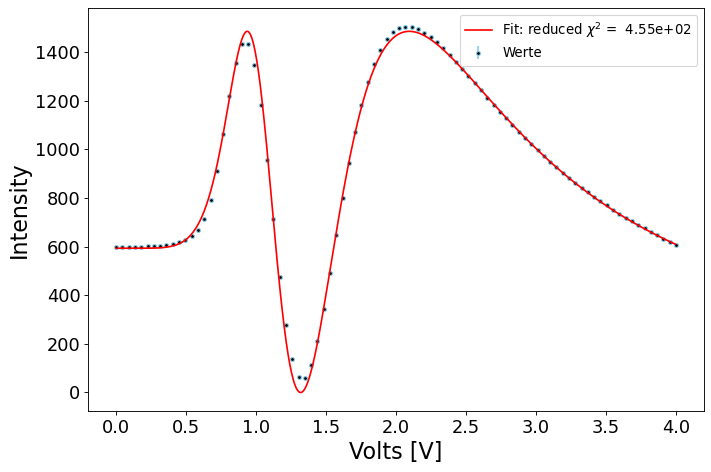

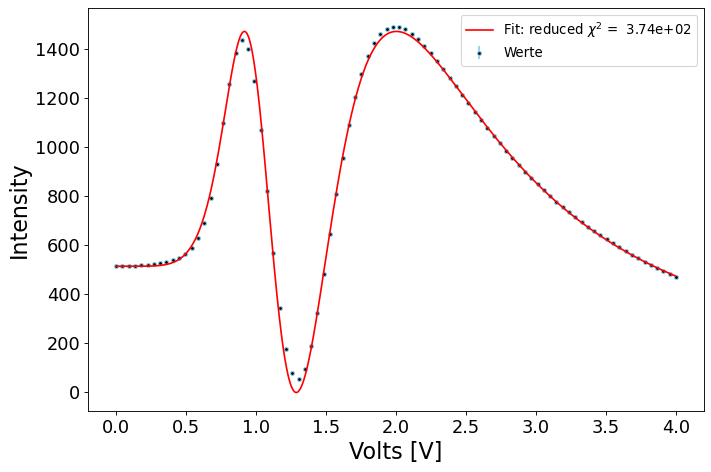

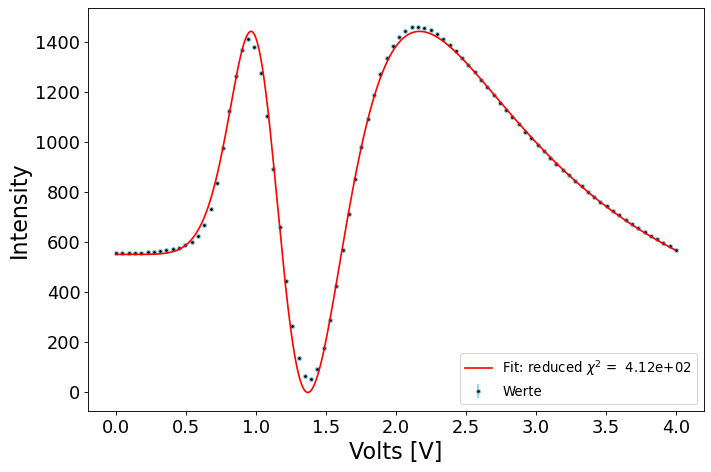

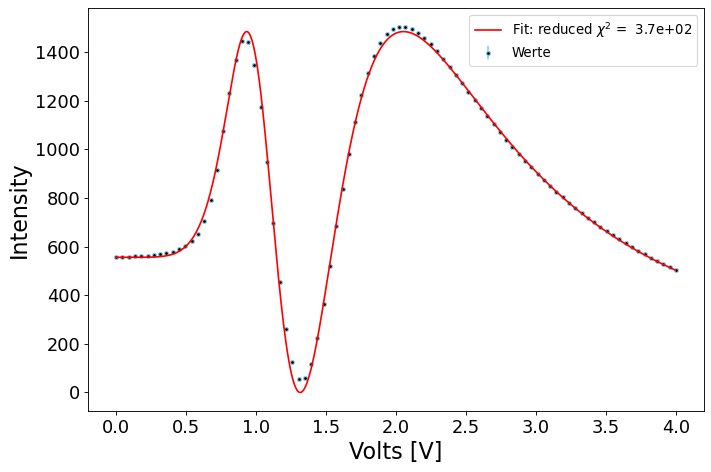

In [31]:
name = "Run1"
# Ordner erstellen
# createArchitecture(name)
# Kurven Fitten
Calibration_Data = Datensatz(name)
Calibration_Data.fitLCR()
# Spannungen für gewollte retardierungen berechnen und abspeichern
Ret = np.arange(0.7, 12, 0.1)
Calibration_Data.getVoltageMap(Ret)
# EV Calibration durchführen
# Optional die idealen Mueller Matrizen der Proben angeben, ansonsten werden die Standardwerte verwendet
# Proben = np.array([np.eye(4), MuellerLinearPolarizer(0), MuellerLinearPolarizer(45), MuellerRetarder(90,0)])
Calibration_Data.ecm_calibrate() # (Proben)

/tmp/ipykernel_35592/330583179.py:110: RuntimeWarning: invalid value encountered in power
  return c * np.power((np.power(b/(x-a), 1/e)-1), 1/d)


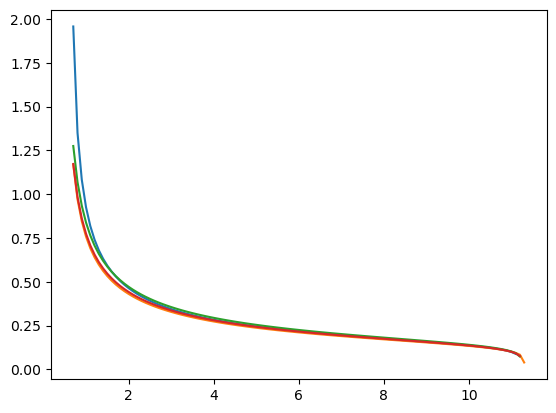

In [28]:
Ret = np.arange(0.7, 12, 0.1)
Voltages = Calibration_Data.getVoltageMap(Ret)
plt.plot(Ret, Voltages[0]/(2*np.pi), label = "LCR1")  
plt.plot(Ret, Voltages[1]/(2*np.pi), label = "LCR2")  
plt.plot(Ret, Voltages[2]/(2*np.pi), label = "LCR1")  
plt.plot(Ret, Voltages[3]/(2*np.pi), label = "LCRw")  

In [34]:
with open(f'./data/{name}/CalibratedAW.npy', 'rb') as f:
    A = np.load(f)
    W = np.load(f)
A, W

(array([[ 0.25      ,  0.05167373, -0.19394552,  0.14904666],
        [ 0.24999991,  0.24725052, -0.00227981,  0.03690504],
        [ 0.24999999,  0.03142146, -0.19615858, -0.15177093],
        [ 0.2500001 , -0.06814282,  0.19148822,  0.14556366],
        [ 0.24999999,  0.00767774,  0.15057728, -0.19941801],
        [ 0.24999983, -0.24002806, -0.00640492,  0.06960949]]),
 array([[ 1.00000046,  0.9999997 ,  0.99999986,  1.00000034,  1.00000001,
          0.99999964],
        [ 0.20669515,  0.98900248,  0.12568583, -0.27257127,  0.03071091,
         -0.96011299],
        [-0.7757831 , -0.00911952, -0.78463421,  0.76595272,  0.60231041,
         -0.02562013],
        [-0.59618595, -0.14761991,  0.60708526, -0.58225584,  0.79767219,
         -0.27843798]]))

# Skript

In [2]:
from MuellerLib import *
from tifffile import imwrite, imread
from tqdm import tqdm

Proben = np.array([np.eye(4), MuellerLinearPolarizer(0), MuellerLinearPolarizer(45), MuellerRetarder(90,0)])
cmw = imread("data/CalData_Example.tif")
A, W, eps, s = ecm_calibrate(cmw, Proben)

BigSRes = imread("data/SRes_Example.tif")
# BigSRes = np.tile(SRes.reshape(256,256,36), (8, 8, 1)) # Nur weil tif datei zu groß
pictureDim1, pictureDim2 = BigSRes.shape[0], BigSRes.shape[1]
Reconst = np.zeros(((pictureDim1, pictureDim2, 16)))
MMD_LD  = np.zeros((pictureDim1, pictureDim2))
MMD_LD_Ori = np.zeros((pictureDim1, pictureDim2))
MMD_LR = np.zeros((pictureDim1, pictureDim2))
MMD_psi = np.zeros((pictureDim1, pictureDim2))

for i in tqdm(range(pictureDim1)):
	Reconst[i,:,:] = reconstMueller(A, BigSRes[i,:,:], W).reshape(-1, 16)
	MMD_LR[i], MMD_psi[i], MMD_LD[i], MMD_LD_Ori[i] = differentialDecompositionFull(Reconst[i,:,:].reshape(-1, 4, 4))

FileNotFoundError: [Errno 2] No such file or directory: '/home/tim/Dokumente/GitReps/Masterarbeit/data/CalData_Example.tif'

In [ ]:
plt.figure(figsize=(24, 16))
plt.subplot(2, 2, 1)
plt.title("Original Image")
OrigImage = Probe.reshape(256, 256, 4, 4)
OrigImage = OrigImage.transpose(2, 0, 3, 1)
OrigImage = OrigImage.reshape(4*256, 4*256)
plt.imshow(OrigImage, cmap="viridis")
plt.colorbar()

plt.subplot(2, 2, 2)
plt.title("Reconstructed Image")
RecImage = Reconst.reshape(256, 256, 4, 4)
RecImage = RecImage.transpose(2, 0, 3, 1)
RecImage = RecImage.reshape(4*256, 4*256)
plt.imshow(RecImage, cmap="viridis")
plt.colorbar()

plt.subplot(2,2,3)
plt.title("Reconstruction Error")
Error = OrigImage-RecImage
plt.imshow(Error, cmap="viridis")
plt.colorbar()

plt.show()

plt.figure(figsize=(24, 32))
plt.subplot(3, 2, 1)
plt.title("Diattenuation")
plt.imshow(MMD_LD.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3, 2, 2)
plt.title("Depolarization")
plt.imshow(MMD_LD_Ori.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,3)
plt.title("Linear Retardance")
plt.imshow(MMD_LR.reshape(256,256), cmap="viridis")
plt.colorbar()

# plt.subplot(3,2,4)
# plt.title("Circular Retardance")
# plt.imshow(MMD_CR.reshape(256,256), cmap="viridis")
# plt.colorbar()

plt.subplot(3,2,5)
plt.title("Orientation")
plt.imshow(MMD_psi.reshape(256,256), cmap="viridis")
plt.colorbar()

In [1]:
from MuellerLib import *
createArchitecture("Run1")